In [1]:
import pennylane as qp
import numpy as np
import matplotlib.pyplot as plt

In [3]:
p = np.array([
    0.30,
    0.20,
    0.15,
    0.10,
    0.10,
    0.05,
    0.05,
    0.05
])

print("Sum of probabilities:", np.sum(p))
print("Number of states:", len(p))

Sum of probabilities: 1.0
Number of states: 8


In [5]:
t = 1.0

exact_phases = t * p

print("Exact phases:")
for x, phase in enumerate(exact_phases):
    print(f"x={x}: phase={phase:.4f}")

Exact phases:
x=0: phase=0.3000
x=1: phase=0.2000
x=2: phase=0.1500
x=3: phase=0.1000
x=4: phase=0.1000
x=5: phase=0.0500
x=6: phase=0.0500
x=7: phase=0.0500


In [6]:
M = 1000

samples = np.random.choice(
    len(p),
    size=M,
    p=p
)

print(samples[:20])

[6 1 3 1 0 2 5 3 0 0 1 7 2 2 1 4 0 6 5 2]


In [8]:
counts = np.bincount(samples, minlength=len(p))

p_hat = counts / M

print("True p:")
print(p)

print("\nEstimated p:")
print(p_hat)

True p:
[0.3  0.2  0.15 0.1  0.1  0.05 0.05 0.05]

Estimated p:
[0.292 0.192 0.161 0.1   0.093 0.06  0.058 0.044]


In [9]:
estimated_phases = t * p_hat

print("\nEstimated phases:")
for x, phase in enumerate(estimated_phases):
    print(f"x={x}: phase={phase:.4f}")


Estimated phases:
x=0: phase=0.2920
x=1: phase=0.1920
x=2: phase=0.1610
x=3: phase=0.1000
x=4: phase=0.0930
x=5: phase=0.0600
x=6: phase=0.0580
x=7: phase=0.0440


In [10]:
num_qubits = 3
wires = list(range(num_qubits))

exact_diagonal = np.exp(1j * exact_phases)
estimated_diagonal = np.exp(1j * estimated_phases)

print("Exact diagonal:")
print(exact_diagonal)

print("\nEstimated diagonal:")
print(estimated_diagonal)

Exact diagonal:
[0.95533649+0.29552021j 0.98006658+0.19866933j 0.98877108+0.14943813j
 0.99500417+0.09983342j 0.99500417+0.09983342j 0.99875026+0.04997917j
 0.99875026+0.04997917j 0.99875026+0.04997917j]

Estimated diagonal:
[0.95767005+0.28786814j 0.98162455+0.19082252j 0.98706747+0.16030535j
 0.99500417+0.09983342j 0.99567862+0.092866j   0.99820054+0.05996401j
 0.99831847+0.05796749j 0.99903216+0.0439858j ]


In [11]:
dev = qp.device("default.qubit", wires=num_qubits)

In [12]:
@qp.qnode(dev)
def exact_oracle_circuit():
    
    # Put all 8 computational basis states
    # into an equal superposition
    for wire in wires:
        qp.Hadamard(wires=wire)
    
    # Apply the ideal phase oracle
    qp.DiagonalQubitUnitary(
        exact_diagonal,
        wires=wires
    )
    
    return qp.state()

In [13]:
exact_state = exact_oracle_circuit()

print(exact_state)

[0.33776245+0.10448217j 0.34650586+0.07024022j 0.34958337+0.05283436j
 0.3517871 +0.03529644j 0.3517871 +0.03529644j 0.35311154+0.0176703j
 0.35311154+0.0176703j  0.35311154+0.0176703j ]


In [14]:
@qp.qnode(dev)
def qos_oracle_circuit():
    
    for wire in wires:
        qp.Hadamard(wires=wire)
    
    qp.DiagonalQubitUnitary(
        estimated_diagonal,
        wires=wires
    )
    
    return qp.state()

In [15]:
qos_state = qos_oracle_circuit()

print(qos_state)

[0.33858749+0.10177676j 0.34705669+0.06746595j 0.34898105+0.0566765j
 0.3517871 +0.03529644j 0.35202555+0.03283309j 0.35291719+0.02120048j
 0.35295888+0.0204946j  0.35321121+0.01555133j]


In [16]:
overlap = np.vdot(exact_state, qos_state)

fidelity = np.abs(overlap) ** 2

print("Overlap:", overlap)
print("Fidelity:", fidelity)

Overlap: (0.9999688752115926-2.624978781562426e-08j)
Fidelity: 0.9999377513919381


In [17]:
sample_phases = np.zeros(len(p))

phase_increment = t / M

for sample in samples:
    sample_phases[sample] += phase_increment

print("Phases accumulated sample-by-sample:")
for x, phase in enumerate(sample_phases):
    print(f"x={x}: phase={phase:.4f}")

print("\nPhases from p_hat:")
print(estimated_phases)

print("\nDifference:")
print(sample_phases - estimated_phases)

Phases accumulated sample-by-sample:
x=0: phase=0.2920
x=1: phase=0.1920
x=2: phase=0.1610
x=3: phase=0.1000
x=4: phase=0.0930
x=5: phase=0.0600
x=6: phase=0.0580
x=7: phase=0.0440

Phases from p_hat:
[0.292 0.192 0.161 0.1   0.093 0.06  0.058 0.044]

Difference:
[2.22044605e-16 1.38777878e-16 1.11022302e-16 6.93889390e-17
 6.93889390e-17 4.85722573e-17 4.16333634e-17 3.46944695e-17]


In [18]:
sample_diagonal = np.exp(1j * sample_phases)

@qp.qnode(dev)
def sample_by_sample_qos_circuit():
    
    for wire in wires:
        qp.Hadamard(wires=wire)
    
    qp.DiagonalQubitUnitary(
        sample_diagonal,
        wires=wires
    )
    
    return qp.state()

sample_qos_state = sample_by_sample_qos_circuit()

overlap_sample = np.vdot(exact_state, sample_qos_state)
fidelity_sample = np.abs(overlap_sample) ** 2

print("Sample-by-sample QOS fidelity:", fidelity_sample)

Sample-by-sample QOS fidelity: 0.9999377513919381


In [19]:
def apply_qos_sample_update(sample, num_states, phase_increment, wires):
    """
    Apply one QOS phase update corresponding to one observed sample.

    Only the computational basis state matching `sample`
    receives the phase exp(i * phase_increment).
    """
    
    diagonal = np.ones(num_states, dtype=complex)
    diagonal[sample] = np.exp(1j * phase_increment)
    
    qp.DiagonalQubitUnitary(
        diagonal,
        wires=wires
    )

In [20]:
@qp.qnode(dev)
def sequential_qos_circuit():
    
    # Equal superposition over all possible addresses
    for wire in wires:
        qp.Hadamard(wires=wire)
    
    # Process samples one at a time
    for sample in samples:
        apply_qos_sample_update(
            sample=sample,
            num_states=len(p),
            phase_increment=phase_increment,
            wires=wires
        )
    
    return qp.state()

In [21]:
sequential_qos_state = sequential_qos_circuit()

print(sequential_qos_state)

[0.33858749+0.10177676j 0.34705669+0.06746595j 0.34898105+0.0566765j
 0.3517871 +0.03529644j 0.35202555+0.03283309j 0.35291719+0.02120048j
 0.35295888+0.0204946j  0.35321121+0.01555133j]


In [22]:
overlap_aggregated = np.vdot(
    qos_state,
    sequential_qos_state
)

fidelity_aggregated = np.abs(overlap_aggregated) ** 2

print(
    "Fidelity: sequential vs aggregated QOS =",
    fidelity_aggregated
)

Fidelity: sequential vs aggregated QOS = 1.0000000000000004


In [23]:
overlap_exact = np.vdot(
    exact_state,
    sequential_qos_state
)

fidelity_exact = np.abs(overlap_exact) ** 2

print(
    "Fidelity: sequential QOS vs exact oracle =",
    fidelity_exact
)

Fidelity: sequential QOS vs exact oracle = 0.9999377513919394


In [24]:
sample_sizes = [10, 25, 50, 100, 250, 500, 1000, 2500, 5000]

fidelities = []

for M_test in sample_sizes:
    test_samples = np.random.choice(
        len(p),
        size=M_test,
        p=p
    )

    test_counts = np.bincount(
        test_samples,
        minlength=len(p)
    )

    test_p_hat = test_counts / M_test
    test_phases = t * test_p_hat
    test_diagonal = np.exp(1j * test_phases)

    @qp.qnode(dev)
    def test_qos_circuit():
        for wire in wires:
            qp.Hadamard(wires=wire)

        qp.DiagonalQubitUnitary(
            test_diagonal,
            wires=wires
        )

        return qp.state()

    test_state = test_qos_circuit()

    overlap = np.vdot(
        exact_state,
        test_state
    )

    fidelity = np.abs(overlap) ** 2
    fidelities.append(fidelity)

for M_test, fidelity in zip(sample_sizes, fidelities):
    print(
        f"M={M_test:5d}   Fidelity={fidelity:.8f}"
    )

M=   10   Fidelity=0.98880571
M=   25   Fidelity=0.99720503
M=   50   Fidelity=0.99895049
M=  100   Fidelity=0.99765360
M=  250   Fidelity=0.99966805
M=  500   Fidelity=0.99966607
M= 1000   Fidelity=0.99993125
M= 2500   Fidelity=0.99998524
M= 5000   Fidelity=0.99997623


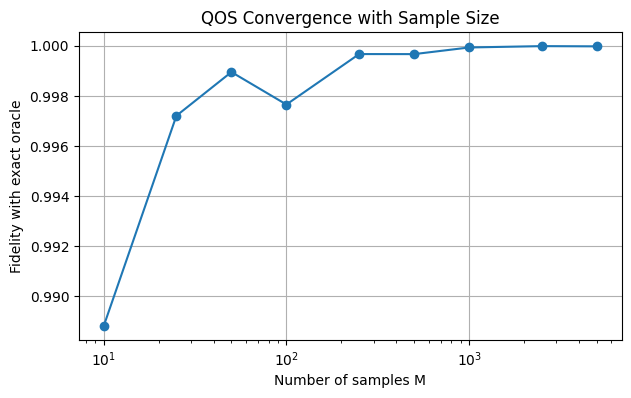

In [25]:
plt.figure(figsize=(7, 4))

plt.plot(
    sample_sizes,
    fidelities,
    marker="o"
)

plt.xscale("log")

plt.xlabel("Number of samples M")
plt.ylabel("Fidelity with exact oracle")
plt.title("QOS Convergence with Sample Size")

plt.grid(True)

plt.show()

In [28]:
sample_sizes = [10, 25, 50, 100, 250, 500, 1000, 2500, 5000]

num_trials = 50

mean_fidelities = []
std_fidelities = []

for M_test in sample_sizes:

    trial_fidelities = []

    for _ in range(num_trials):

        # Draw a new independent dataset
        test_samples = np.random.choice(
            len(p),
            size=M_test,
            p=p
        )

        # Estimate p(x)
        test_counts = np.bincount(
            test_samples,
            minlength=len(p)
        )

        test_p_hat = test_counts / M_test

        # Construct approximate QOS phases
        test_phases = t * test_p_hat
        test_diagonal = np.exp(1j * test_phases)

        # Since we know the state analytically here,
        # construct it directly
        test_state = (
            test_diagonal / np.sqrt(len(p))
        )

        # Compare against exact oracle state
        overlap = np.vdot(
            exact_state,
            test_state
        )

        fidelity = np.abs(overlap) ** 2
        trial_fidelities.append(fidelity)

    mean_fidelities.append(
        np.mean(trial_fidelities)
    )

    std_fidelities.append(
        np.std(trial_fidelities)
    )


for M_test, mean_fid, std_fid in zip(
    sample_sizes,
    mean_fidelities,
    std_fidelities
):
    print(
        f"M={M_test:5d}   "
        f"Mean fidelity={mean_fid:.8f}   "
        f"Std={std_fid:.8f}"
    )

M=   10   Mean fidelity=0.98840418   Std=0.00519861
M=   25   Mean fidelity=0.99607584   Std=0.00230482
M=   50   Mean fidelity=0.99801434   Std=0.00093666
M=  100   Mean fidelity=0.99902707   Std=0.00056434
M=  250   Mean fidelity=0.99964323   Std=0.00017801
M=  500   Mean fidelity=0.99978533   Std=0.00013231
M= 1000   Mean fidelity=0.99988506   Std=0.00009032
M= 2500   Mean fidelity=0.99996003   Std=0.00002486
M= 5000   Mean fidelity=0.99998251   Std=0.00001206


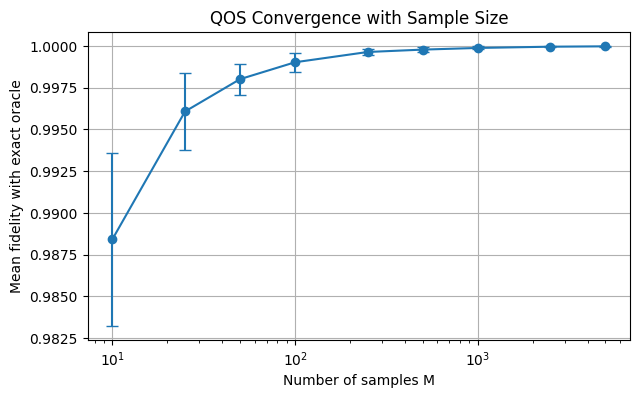

In [29]:
plt.figure(figsize=(7, 4))

plt.errorbar(
    sample_sizes,
    mean_fidelities,
    yerr=std_fidelities,
    marker="o",
    capsize=4
)

plt.xscale("log")

plt.xlabel("Number of samples M")
plt.ylabel("Mean fidelity with exact oracle")
plt.title("QOS Convergence with Sample Size")

plt.grid(True)

plt.show()